# 03 · Cookie Cats A/B test (real, randomized)
This analysis follows `docs/pre_analysis_plan_cookie_cats.md`, which was committed before this notebook ran. That plan is a timestamped commit, not a true pre-registration.
**Missing guardrail:** revenue. Gate placement drives in-app purchases, and the data has none.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 4)
FIG = ROOT / "reports" / "figures"

In [2]:
from src.analysis import cookie_cats as cc
r = cc.run()

## Validity checks

In [3]:
print('n', r['n']); print('SRM', r['srm']); print('duplicate userids', r['duplicate_userids']); r['rounds_outliers']

n {'gate_30': 44700, 'gate_40': 45489}
SRM {'n_control': 44700, 'n_treatment': 45489, 'expected_share': 0.5, 'observed_share': 0.5043741476233243, 'chi2': 6.9024049496058275, 'p_value': 0.008607987810836243, 'srm_detected': False, 'threshold': 0.001, 'flag_at_0_01': True}
duplicate userids 0


{'max': 49854,
 'p99_9': 1073.6240000000107,
 'n_above_p99_9': 91,
 'n_zero_rounds': 3994,
 'max_row': {'userid': 6390605,
  'version': 'gate_30',
  'sum_gamerounds': 49854,
  'retention_1': False,
  'retention_7': True}}

**SRM:** p ≈ 0.009. This is below 0.01 but above the pre-specified 0.001 flag threshold, so the plan treats it as not flagged and reports it openly. The imbalance (50.4% in gate_40) is small, and it would only bias the result if assignment or logging depended on the outcome.

## Primary: D7 retention

In [4]:
m = r['primary_d7']
print(f"gate_30 {m['rate_control']:.4f}  gate_40 {m['rate_treatment']:.4f}")
print(f"diff {100*m['abs_diff']:+.3f} pp  Newcombe CI [{100*m['ci_low']:+.3f}, {100*m['ci_high']:+.3f}]  bootstrap [{100*m['bootstrap']['ci_low']:+.3f}, {100*m['bootstrap']['ci_high']:+.3f}]")
print(f"relative lift {m['relative_lift']:+.2%}  p = {m['p_value']:.4f}")
r['interpretation_of_interval']

gate_30 0.1902  gate_40 0.1820
diff -0.820 pp  Newcombe CI [-1.328, -0.312]  bootstrap [-1.332, -0.316]
relative lift -4.31%  p = 0.0016


{'ci_pp': [-1.3281940871914826, -0.31213026887613],
 'rules_out_gain_of_min_effect': True,
 'rules_out_any_gain': True}

## Guardrails (non-inferiority)

In [5]:
g = r['guardrail_d1']; print('D1', round(100*g['abs_diff'],3), [round(100*g['ci_low'],3), round(100*g['ci_high'],3)], g['status'])
r['guardrail_rounds']

D1 -0.591 [-1.239, 0.058] not_pass


{'winsorized_mean_diff': {'estimate': -0.09564444917356241,
  'ci_low': -1.3693487269951505,
  'ci_high': 1.1678047791375425,
  'n_boot': 10000,
  'seed': 2026},
 'raw_mean_diff': {'estimate': -1.157488453953249,
  'ci_low': -4.10003485041225,
  'ci_high': 1.0057810089717119,
  'n_boot': 10000,
  'seed': 2026},
 'median_diff': {'estimate': -1.0,
  'ci_low': -1.0,
  'ci_high': 0.0,
  'n_boot': 2000,
  'seed': 2026},
 'mann_whitney_p': 0.05020880772044255,
 'winsor_cap': 1073.6240000000107,
 'ni_margin_rounds': 2.5,
 'status': 'pass',
 'means': {'gate_30_winsorized': 51.03090791946309,
  'gate_40_winsorized': 50.93526347028953}}

## Power (no observed power)

In [6]:
{k: v for k, v in r['power'].items() if k != 'curve'}

{'baseline_d7': 0.19020134228187918,
 'mde_at_80pct_power_pp': 0.7376150061811748,
 'n_per_arm_for_0_5pp': 95734}

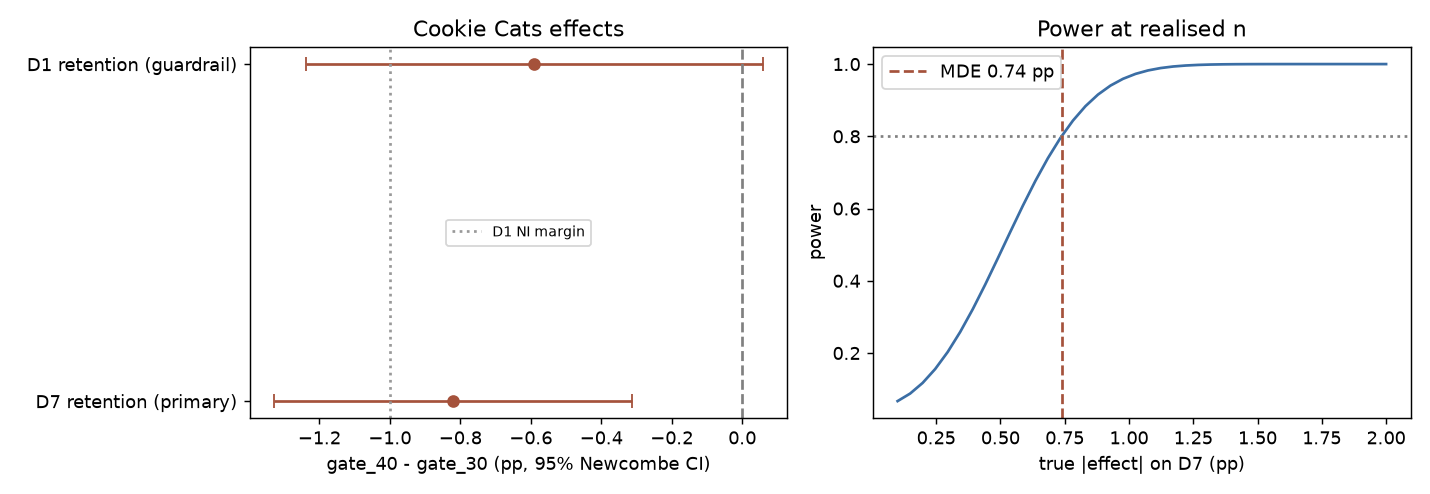

In [7]:
display(Image(FIG / 'cookie_cats_effects.png'))

## Decision

In [8]:
print(r['decision'], '-', r['decision_reason']); r['cannot_support']

do_not_ship - gate_40 lowered D7 retention (CI entirely below 0). Keep the gate at level 30. This is the failed-experiment case.


['revenue impact',
 'day-30 retention',
 'novelty effects (no timestamps)',
 'segment effects (no pre-treatment covariates)']

## Failed-experiment case study
**What happened.** Moving the gate to level 40 *lowered* D7 retention by about 0.8 pp (a 4% relative drop). The CI excludes zero and excludes any gain. D1 retention is also lower, but its CI crosses the 1 pp non-inferiority margin, so that guardrail **does not pass**. The robust (winsorized) mean of rounds played is unchanged.

**What we learned.** An earlier forced break is associated with better week-one retention. One plausible mechanism is that the gate rations play and protects against burnout. That mechanism is a hypothesis, not something the test identified.

**What to test next.** Keep gate_30 and test an *earlier* gate (for example, level 25) or a shorter wait, with revenue per player as a pre-specified guardrail. Detecting a 0.5 pp change in D7 needs about 95,700 players per arm.